# 16. 별도 LSTM 다음3분 공정 변수 예측
    기존CNN유형진단과분리한회귀과제다. 과거20×52→다음52개변수를예측한다.
    정상Train400개family만학습하고동일Validation100/Test500분할을유지했다. 이노트북은저장결과만읽고재학습하지않는다.

In [1]:
from pathlib import Path
import json,pandas as pd,numpy as np
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/phase2.json').exists())
OUT=ROOT/'reports/next_step_forecasting'
def table(name):return pd.read_csv(OUT/'tables'/name)
def show(frame):display(frame.style.hide(axis='index').format(precision=5,na_rep='해당없음'))
def image(name):display(Image(filename=str(OUT/'figures'/name)))
v=json.loads((OUT/'validation.json').read_text())
assert not v['cnn_modified'] and not v['forecast_values_fed_to_CNN'] and not v['test_selection_or_tuning']

## 1. 정상 패턴 학습과 Validation 선택
    LSTM64·2layers·residual현재값출력, Huber loss, AdamW. 예측값을기존CNN에넣지않았다.
    정상Train의평균/표준편차만fit했다. 모든입력은target보다앞선20개관측이다.

seed,epoch,validation_normalized_mse,persistence_validation_mse,train_windows,validation_windows,training_seconds,device
42,12,0.57570,0.99501,48000,48000,14.07334,cuda
7,12,0.57229,0.99501,48000,48000,12.98693,cuda
2026,12,0.57642,0.99501,48000,48000,11.66094,cuda


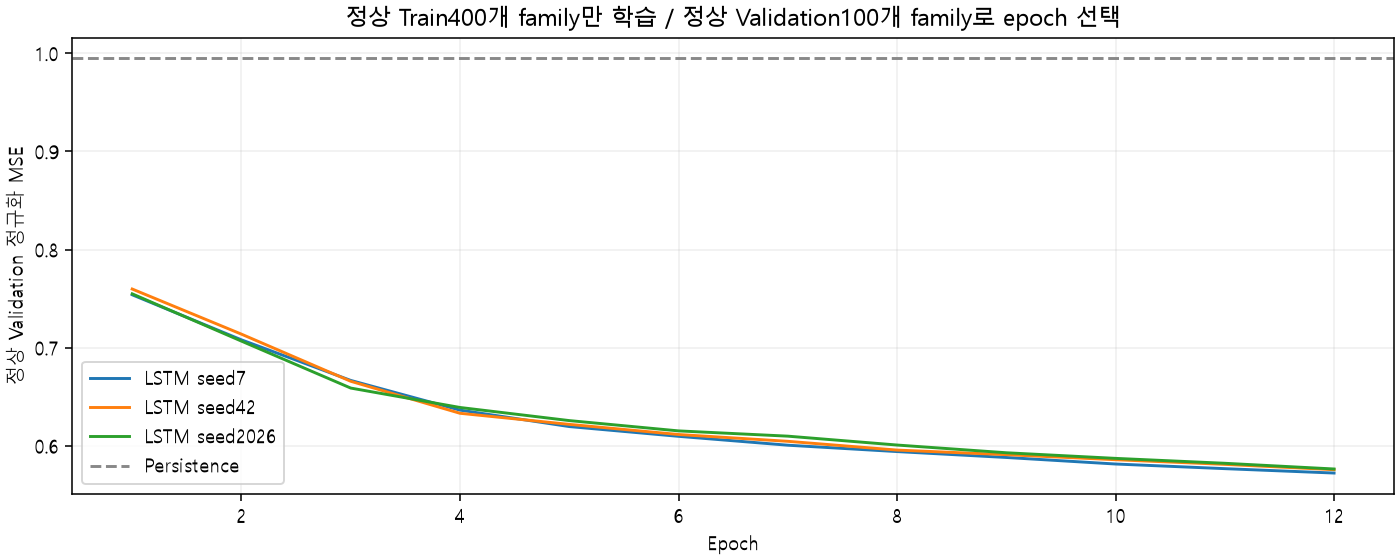

In [2]:
show(table('validation_summary.csv'))
image('validation_learning.png')

## 2. 전체 Test: 단순 Persistence와 비교
    다음값=현재값 기준선과같은target에서비교한다. 대표seed42,전체9,870,000개target이다.
    RMSE가좋아도MAE가나빠질수있으며실제로전체/고장후MAE는LSTM이더나빴다. 특정지표만으로우수성을단정하지않는다.

model,cohort,target_rows,normalized_rmse,normalized_mae
LSTM,all,9870000,1.49432,0.73783
LSTM,healthy_context,1870000,0.75780,0.53381
LSTM,post_fault,8000000,1.61886,0.78552
LSTM,faultfree_only,470000,0.75806,0.53401
Persistence,all,9870000,1.63014,0.69053
Persistence,healthy_context,1870000,0.99630,0.63653
Persistence,post_fault,8000000,1.74542,0.70315
Persistence,faultfree_only,470000,0.99628,0.63668


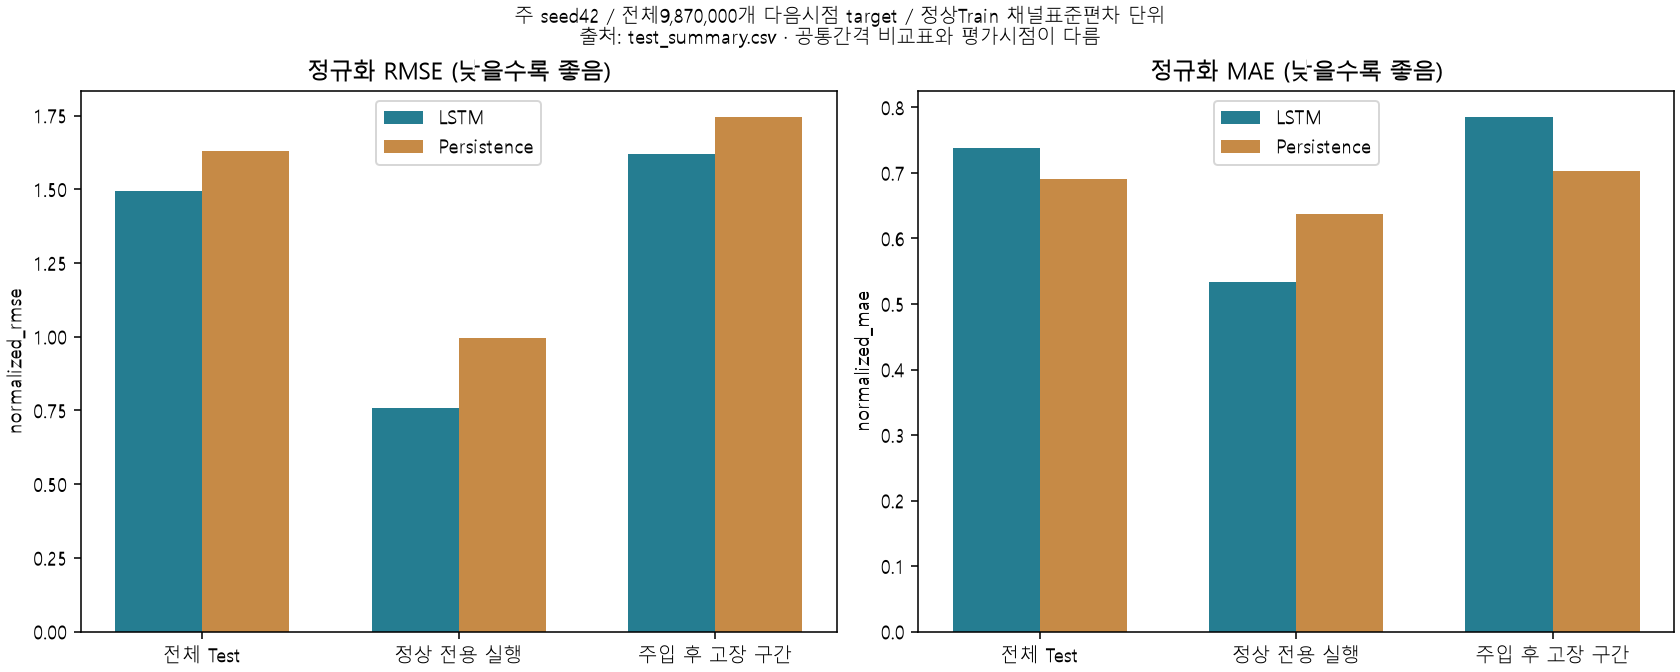

model,cohort,variable,target_rows,normalized_rmse,normalized_mae,raw_rmse,raw_mae,raw_unit
LSTM,all,xmeas_1,9870000,0.78761,0.53546,0.02431,0.01653,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_2,9870000,0.92025,0.71283,31.32560,24.26512,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_3,9870000,0.87112,0.68125,34.12858,26.68971,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_4,9870000,1.17419,0.90639,0.10072,0.07775,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_5,9870000,1.26338,0.98188,0.26698,0.20750,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_6,9870000,1.21837,0.96361,0.26610,0.21046,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_7,9870000,0.44962,0.29462,3.39078,2.22191,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_8,9870000,1.12900,0.88602,0.61202,0.48031,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_9,9870000,4.73798,1.83802,0.09046,0.03509,UNKNOWN; B column units not independently verified
LSTM,all,xmeas_10,9870000,0.72073,0.52879,0.00903,0.00663,UNKNOWN; B column units not independently verified


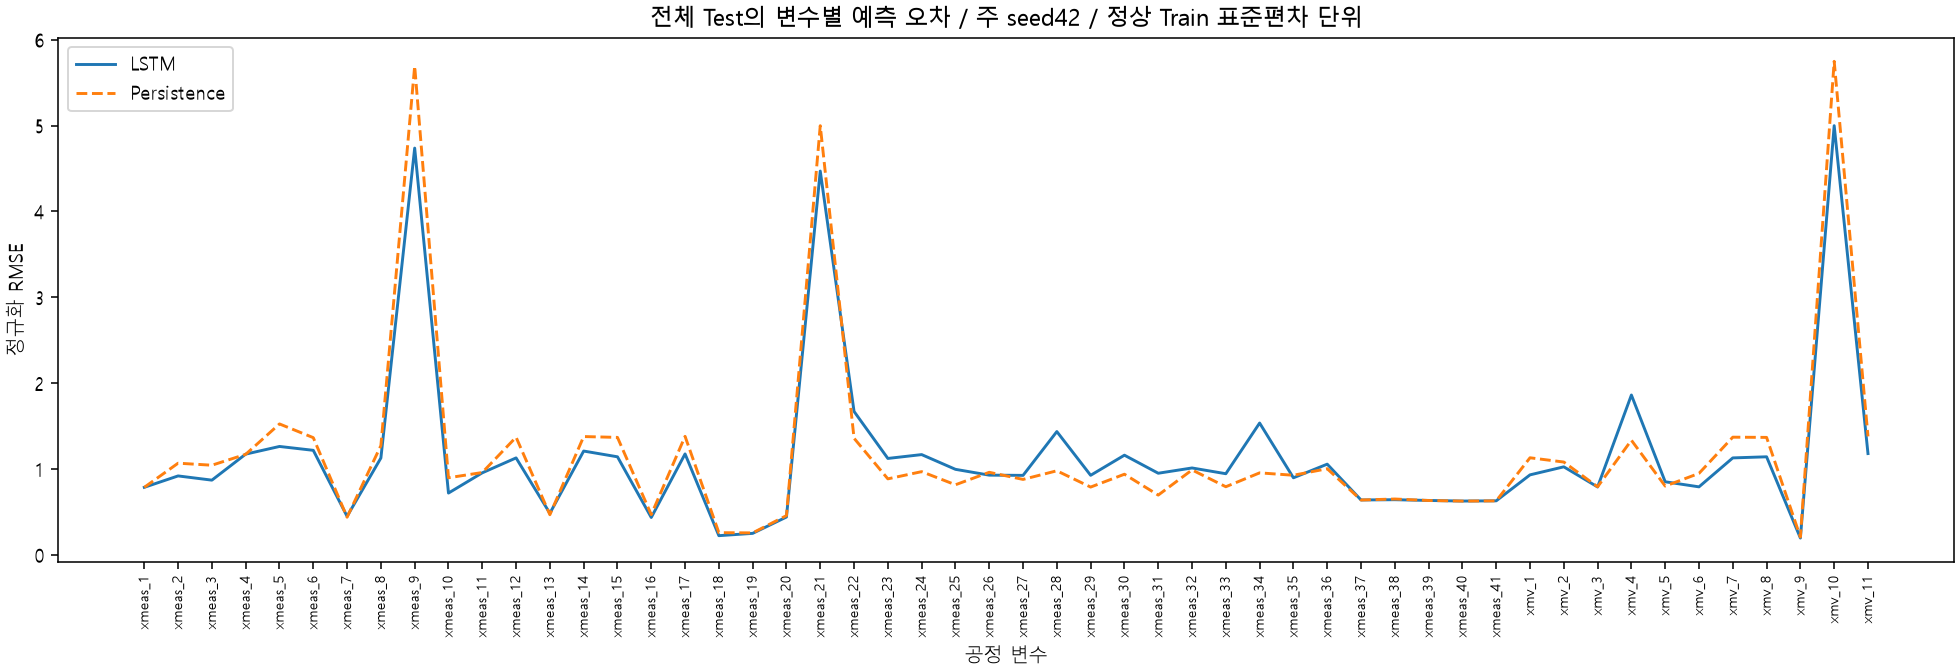

In [3]:
results=table('test_summary.csv')
show(results[(results.seed==42)&(results['mode']=='dense')][['model','cohort','target_rows','normalized_rmse','normalized_mae']])
image('lstm_vs_persistence.png')
show(table('per_variable_metrics.csv').query('cohort == "all"'))
image('per_variable_forecast_error.png')

## 3.3개 seed와 예측 사례
    공통987,000시점의비교는전체9,870,000시점과표본분포가다르다.두표를섞지않는다.
    변수그래프는정상Train표준편차단위다. B원단위대응은독립검증하지않아UNKNOWN으로기록했다.

model,cohort,rmse_mean,rmse_sd,mae_mean,mae_sd
LSTM,all,1.56857,0.00958,0.83815,0.00298
LSTM,faultfree_only,0.82710,0.00055,0.59325,0.00028
LSTM,healthy_context,0.82638,0.00054,0.59272,0.00026
LSTM,post_fault,1.69585,0.01089,0.89551,0.00362
Persistence,all,1.77009,0.00000,0.96151,0.00000
Persistence,faultfree_only,1.19691,0.00000,0.89893,0.00000
Persistence,healthy_context,1.19541,0.00000,0.89762,0.00000
Persistence,post_fault,1.87925,0.00000,0.97644,0.00000


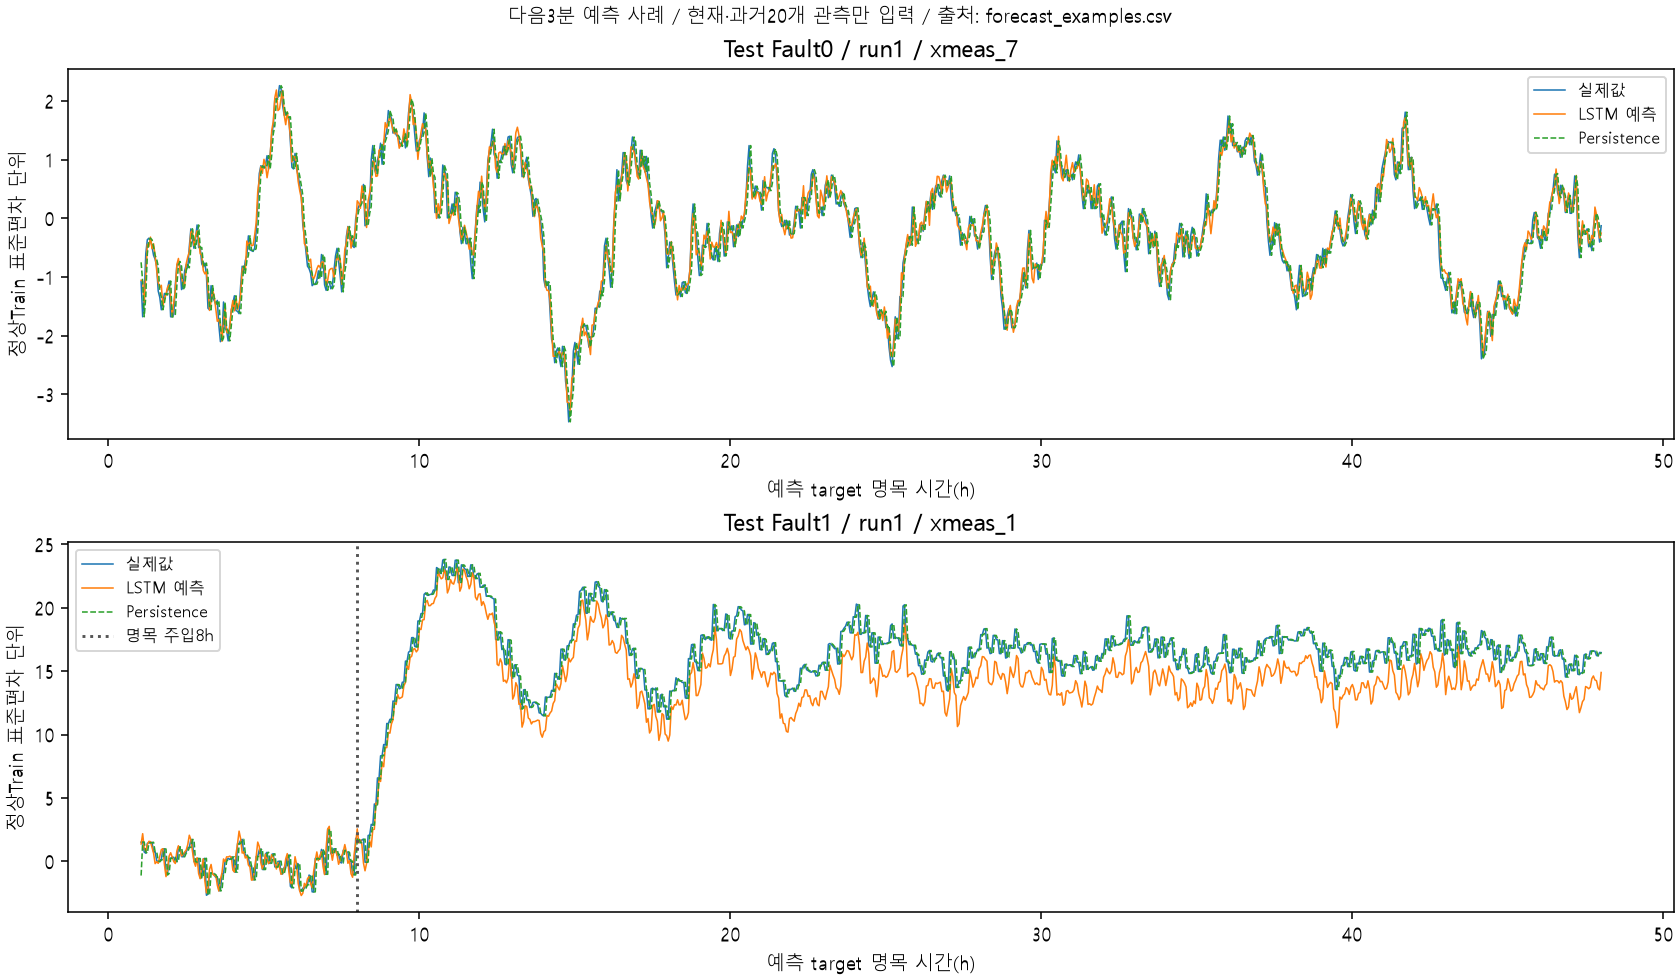

In [4]:
show(table('common_seed_summary.csv'))
image('forecast_examples.png')

## 4. 기능과 해석 범위
    예측기는다음3분변수값을반환한다. 고장ID·고장원인·RUL을예측하는기능이아니다.
    원래CNN의21출력·입력·threshold는그대로다. 예측잔차의새경보임계값도고르지않았다.
    `python experiments/next_step_forecasting/predict.py --input one_run.csv --output next_step_predictions.csv`로사용한다.
    52개필수열·한실행·연속관측·20개이력조건을지켜야하며결측은대체하지않는다.